In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Step 1: Load data 

In [4]:
df = pd.read_csv("data/vgsales.csv")
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [5]:
df.shape

(16598, 11)

## Step 2: Data Cleaning
- Check: missing values and fix
- Check: hidden missing values and fix
- Check: duplicates and fix


# Missing values and fix

In [6]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [7]:
print("Before:", df.shape)
df = df.dropna(subset=["Year", "Publisher"])
print("After:", df.shape)

Before: (16598, 11)
After: (16291, 11)


In [8]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

# Check: hidden missing values and Fix

In [9]:
df["Genre"].unique()

<StringArray>
[      'Sports',     'Platform',       'Racing', 'Role-Playing',
       'Puzzle',         'Misc',      'Shooter',   'Simulation',
       'Action',     'Fighting',    'Adventure',     'Strategy']
Length: 12, dtype: str

In [10]:
df["Platform"].unique()

<StringArray>
[ 'Wii',  'NES',   'GB',   'DS', 'X360',  'PS3',  'PS2', 'SNES',  'GBA',
  '3DS',  'PS4',  'N64',   'PS',   'XB',   'PC', '2600',  'PSP', 'XOne',
   'GC', 'WiiU',  'GEN',   'DC',  'PSV',  'SAT',  'SCD',   'WS',   'NG',
 'TG16',  '3DO',   'GG', 'PCFX']
Length: 31, dtype: str

In [11]:
df["Publisher"].value_counts().head(20)

Publisher
Electronic Arts                           1339
Activision                                 966
Namco Bandai Games                         928
Ubisoft                                    918
Konami Digital Entertainment               823
THQ                                        712
Nintendo                                   696
Sony Computer Entertainment                682
Sega                                       632
Take-Two Interactive                       412
Capcom                                     376
Atari                                      347
Tecmo Koei                                 338
Square Enix                                231
Warner Bros. Interactive Entertainment     217
Disney Interactive Studios                 214
Eidos Interactive                          196
Midway Games                               196
505 Games                                  192
Microsoft Game Studios                     189
Name: count, dtype: int64

In [12]:
suspicious = ["unknown", "n/a", "na", "none", "null", "-", "?", ""]

for col in ["Name", "Platform", "Genre", "Publisher"]:
    found = df[col].str.lower().str.strip().isin(suspicious).sum()
    print(col, found)

Name 0
Platform 0
Genre 0
Publisher 100


In [13]:
df[df["Publisher"].str.lower().str.strip().isin(suspicious)]["Publisher"].value_counts()

Publisher
Unknown    100
Name: count, dtype: int64

In [14]:
print("Before:", df.shape)
df = df[df["Publisher"] != "Unknown"]
print("After:", df.shape)

Before: (16291, 11)
After: (16191, 11)


# Check: duplicates and fix

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.duplicated(subset=["Name", "Platform", "Year"]).sum()

np.int64(1)

In [17]:
df[df.duplicated(subset=["Name", "Platform", "Year"], keep=False)]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
603,604,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,2.11,0.23,0.0,0.22,2.56
16127,16130,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,0.00,0.01,0.0,0.00,0.01


In [18]:
print("Before:", df.shape)
df = df.drop_duplicates(subset=["Name", "Platform", "Year"], keep="first")
print("After:", df.shape)

Before: (16191, 11)
After: (16190, 11)


# Check: weird values and fix

In [19]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16190.000000,16190.000000,16190.000000,16190.000000,16190.000000,16190.000000,16190.000000
mean,8266.095306,2006.383385,0.266960,0.148422,0.079120,0.048667,0.543442
std,4787.268065,5.833067,0.824764,0.510730,0.312695,0.190629,1.571763
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4115.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8259.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12402.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [20]:
df["Year"].value_counts().sort_index().tail(10)

Year
2009.0    1430
2010.0    1239
2011.0    1094
2012.0     648
2013.0     544
2014.0     577
2015.0     608
2016.0     338
2017.0       3
2020.0       1
Name: count, dtype: int64

In [21]:
df[df["Year"] > 2016]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
5957,5959,Imagine: Makeup Artist,DS,2020.0,Simulation,Ubisoft,0.27,0.0,0.00,0.02,0.29
14390,14393,Phantasy Star Online 2 Episode 4: Deluxe Package,PS4,2017.0,Role-Playing,Sega,0.00,0.0,0.03,0.00,0.03
16241,16244,Phantasy Star Online 2 Episode 4: Deluxe Package,PSV,2017.0,Role-Playing,Sega,0.00,0.0,0.01,0.00,0.01
16438,16441,Brothers Conflict: Precious Baby,PSV,2017.0,Action,Idea Factory,0.00,0.0,0.01,0.00,0.01


In [22]:
df.loc[(df["Name"] == "Imagine: Makeup Artist") & (df["Platform"] == "DS"), "Year"] = 2009

In [23]:
df[df["Year"] > 2016]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
14390,14393,Phantasy Star Online 2 Episode 4: Deluxe Package,PS4,2017.0,Role-Playing,Sega,0.0,0.0,0.03,0.0,0.03
16241,16244,Phantasy Star Online 2 Episode 4: Deluxe Package,PSV,2017.0,Role-Playing,Sega,0.0,0.0,0.01,0.0,0.01
16438,16441,Brothers Conflict: Precious Baby,PSV,2017.0,Action,Idea Factory,0.0,0.0,0.01,0.0,0.01


In [24]:
print("Before:", df.shape)
df = df[df["Year"] <= 2015]
print("After:", df.shape)

Before: (16190, 11)
After: (15849, 11)


In [25]:
# Count categories

In [26]:
df[["Platform", "Genre", "Publisher"]].nunique()

Platform      31
Genre         12
Publisher    563
dtype: int64

In [27]:
df["Publisher"].value_counts().tail(20)

Publisher
Warashi                       1
Lighthouse Interactive        1
Masque Publishing             1
RED Entertainment             1
Michaelsoft                   1
Media Entertainment           1
New World Computing           1
Genterprise                   1
Interworks Unlimited, Inc.    1
Boost On                      1
EON Digital Entertainment     1
Naxat Soft                    1
Ascaron Entertainment         1
Piacci                        1
Otomate                       1
Ongakukan                     1
Commseed                      1
Takuyo                        1
Interchannel-Holon            1
Rain Games                    1
Name: count, dtype: int64

In [28]:
counts = df["Publisher"].value_counts()
print("Publishers with only 1 game:", (counts == 1).sum())
print("Publishers with less than 10 games:", (counts < 10).sum())

Publishers with only 1 game: 183
Publishers with less than 10 games: 413


# Fix: Year to whole numbers

In [29]:
df["Year"] = df["Year"].astype(int)
df["Year"].head()

0    2006
1    1985
2    2008
3    2009
4    1996
Name: Year, dtype: int64

# Final check

In [30]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Unknown publishers:", (df["Publisher"] == "Unknown").sum())
print("Duplicates:", df.duplicated(subset=["Name", "Platform", "Year"]).sum())
print("Year range:", df["Year"].min(), "to", df["Year"].max())

Shape: (15849, 11)
Missing values: 0
Unknown publishers: 0
Duplicates: 0
Year range: 1980 to 2015


# Step 3, make Hit / make label 1,0  

In [31]:
df["Hit"] = (df["Global_Sales"] >= 1).astype(int)
df[["Name", "Global_Sales", "Hit"]].sample(10, random_state=RANDOM_STATE)

,Name,Global_Sales,Hit
15101,Crazy Machines,0.02,0
14632,1000 Cooking Recipes from ELLE à table,0.03,0
14396,Otomedius Gorgeous,0.03,0
6093,Warriors Orochi 2,0.29,0
14988,AMF Xtreme Bowling,0.02,0
10506,Astro Boy: The Video Game,0.10,0
2224,Borderlands 2,0.93,0
3430,Deus Ex: Human Revolution,0.59,0
11222,Charlotte's Web,0.09,0
11033,Cardfight!! Vanguard: Ride to Victory,0.09,0


In [32]:
print(df["Hit"].value_counts())
print(df["Hit"].value_counts(normalize=True) * 100)

Hit
0    13807
1     2042
Name: count, dtype: int64
Hit
0    87.115906
1    12.884094
Name: proportion, dtype: float64


## Step 4: Feature engineering
- Num_Platforms: how many consoles the game is on so far
- Already_Released: was the game already out on another console in an earlier year? (1 = yes, 0 = no)

# Num_Platforms

In [33]:
per_year = df.groupby(["Name", "Year"]).size().reset_index(name="Count")
per_year["Num_Platforms"] = per_year.groupby("Name")["Count"].cumsum()
per_year[per_year["Name"] == "Grand Theft Auto V"]

,Name,Year,Count,Num_Platforms
3820,Grand Theft Auto V,2013,2,2
3821,Grand Theft Auto V,2014,2,4
3822,Grand Theft Auto V,2015,1,5


In [34]:
df = df.merge(per_year[["Name", "Year", "Num_Platforms"]], on=["Name", "Year"], how="left")
df[df["Name"] == "Grand Theft Auto V"][["Name", "Platform", "Year", "Num_Platforms"]]

,Name,Platform,Year,Num_Platforms
16,Grand Theft Auto V,PS3,2013,2
23,Grand Theft Auto V,X360,2013,2
44,Grand Theft Auto V,PS4,2014,4
196,Grand Theft Auto V,XOne,2014,4
1860,Grand Theft Auto V,PC,2015,5


In [35]:
print("Shape:", df.shape)
print("Missing:", df["Num_Platforms"].isnull().sum())
df["Num_Platforms"].value_counts().sort_index()

Shape: (15849, 13)
Missing: 0


Num_Platforms
1     8967
2     2676
3     1823
4     1019
5      634
6      430
7      179
8       89
9       27
11       4
12       1
Name: count, dtype: int64

In [36]:
df[df["Num_Platforms"] >= 11][["Name", "Platform", "Year", "Num_Platforms"]]

,Name,Platform,Year,Num_Platforms
491,Need for Speed: Most Wanted,PS3,2012,11
1153,Need for Speed: Most Wanted,X360,2012,11
1707,Need for Speed: Most Wanted,PSV,2012,11
5981,Need for Speed: Most Wanted,WiiU,2013,12
11295,Need for Speed: Most Wanted,PC,2012,11


In [37]:
df[df["Name"] == "Need for Speed: Most Wanted"][["Name", "Platform", "Year", "Num_Platforms"]].sort_values("Year")

,Name,Platform,Year,Num_Platforms
250,Need for Speed: Most Wanted,PS2,2005,7
1503,Need for Speed: Most Wanted,X360,2005,7
3497,Need for Speed: Most Wanted,GC,2005,7
1967,Need for Speed: Most Wanted,XB,2005,7
5742,Need for Speed: Most Wanted,PC,2005,7
6102,Need for Speed: Most Wanted,DS,2005,7
6307,Need for Speed: Most Wanted,GBA,2005,7
491,Need for Speed: Most Wanted,PS3,2012,11
1707,Need for Speed: Most Wanted,PSV,2012,11
1153,Need for Speed: Most Wanted,X360,2012,11


In [38]:
same_console_twice = df[df.duplicated(subset=["Name", "Platform"], keep=False)]
print("Games affected:", same_console_twice["Name"].nunique())
same_console_twice[["Name", "Platform", "Year"]].sort_values(["Name", "Year"])

Games affected: 1


,Name,Platform,Year
1503,Need for Speed: Most Wanted,X360,2005
5742,Need for Speed: Most Wanted,PC,2005
1153,Need for Speed: Most Wanted,X360,2012
11295,Need for Speed: Most Wanted,PC,2012


# Fix: same name, different game (remake)

In [39]:
df_sorted = df.sort_values("Year")
later_rows = df_sorted[df_sorted.duplicated(subset=["Name", "Platform"], keep="first")]
remake_start = later_rows.groupby("Name")["Year"].min()

for name, year in remake_start.items():
    later = (df["Name"] == name) & (df["Year"] >= year)
    df.loc[later, "Name"] = name + " (Remake)"

print("Games renamed:", len(remake_start))
print(remake_start)

Games renamed: 1
Name
Need for Speed: Most Wanted    2012
Name: Year, dtype: int64


In [40]:
df[df["Name"].str.contains("Most Wanted")][["Name", "Platform", "Year", "Num_Platforms"]].sort_values("Year")

,Name,Platform,Year,Num_Platforms
250,Need for Speed: Most Wanted,PS2,2005,7
774,Need for Speed: Most Wanted 5-1-0,PSP,2005,1
1967,Need for Speed: Most Wanted,XB,2005,7
1503,Need for Speed: Most Wanted,X360,2005,7
3497,Need for Speed: Most Wanted,GC,2005,7
6307,Need for Speed: Most Wanted,GBA,2005,7
6102,Need for Speed: Most Wanted,DS,2005,7
5742,Need for Speed: Most Wanted,PC,2005,7
1707,Need for Speed: Most Wanted (Remake),PSV,2012,11
1153,Need for Speed: Most Wanted (Remake),X360,2012,11


# Rebuild Num_Platforms (after fixing the remake)

In [41]:
df = df.drop(columns=["Num_Platforms"])
per_year = df.groupby(["Name", "Year"]).size().reset_index(name="Count")
per_year["Num_Platforms"] = per_year.groupby("Name")["Count"].cumsum()
df = df.merge(per_year[["Name", "Year", "Num_Platforms"]], on=["Name", "Year"], how="left")

In [42]:
df[df["Name"].str.contains("Most Wanted")][["Name", "Platform", "Year", "Num_Platforms"]].sort_values("Year")

,Name,Platform,Year,Num_Platforms
250,Need for Speed: Most Wanted,PS2,2005,7
774,Need for Speed: Most Wanted 5-1-0,PSP,2005,1
1967,Need for Speed: Most Wanted,XB,2005,7
1503,Need for Speed: Most Wanted,X360,2005,7
3497,Need for Speed: Most Wanted,GC,2005,7
6307,Need for Speed: Most Wanted,GBA,2005,7
6102,Need for Speed: Most Wanted,DS,2005,7
5742,Need for Speed: Most Wanted,PC,2005,7
1707,Need for Speed: Most Wanted (Remake),PSV,2012,4
1153,Need for Speed: Most Wanted (Remake),X360,2012,4


# Already_Released

In [43]:
first_year = df.groupby("Name")["Year"].transform("min")
df["Already_Released"] = (df["Year"] > first_year).astype(int)
df[df["Name"] == "Grand Theft Auto V"][["Name", "Platform", "Year", "Already_Released"]]

,Name,Platform,Year,Already_Released
16,Grand Theft Auto V,PS3,2013,0
23,Grand Theft Auto V,X360,2013,0
44,Grand Theft Auto V,PS4,2014,1
196,Grand Theft Auto V,XOne,2014,1
1860,Grand Theft Auto V,PC,2015,1


In [44]:
print(df["Already_Released"].value_counts())
df[df["Name"].str.contains("Most Wanted")][["Name", "Platform", "Year", "Already_Released"]].sort_values("Year")

Already_Released
0    14948
1      901
Name: count, dtype: int64


,Name,Platform,Year,Already_Released
250,Need for Speed: Most Wanted,PS2,2005,0
774,Need for Speed: Most Wanted 5-1-0,PSP,2005,0
1967,Need for Speed: Most Wanted,XB,2005,0
1503,Need for Speed: Most Wanted,X360,2005,0
3497,Need for Speed: Most Wanted,GC,2005,0
6307,Need for Speed: Most Wanted,GBA,2005,0
6102,Need for Speed: Most Wanted,DS,2005,0
5742,Need for Speed: Most Wanted,PC,2005,0
1707,Need for Speed: Most Wanted (Remake),PSV,2012,0
1153,Need for Speed: Most Wanted (Remake),X360,2012,0


# Step 5: Charts


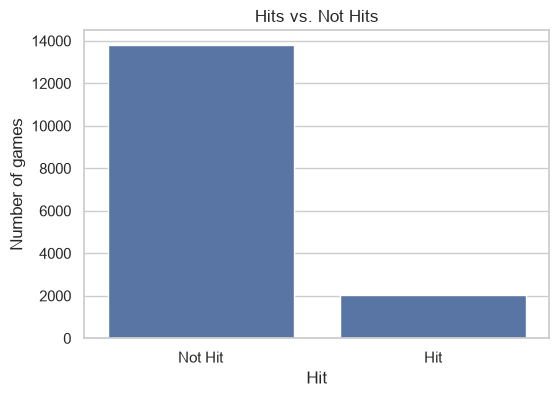

In [45]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Hit")
plt.xticks([0, 1], ["Not Hit", "Hit"])
plt.title("Hits vs. Not Hits")
plt.ylabel("Number of games")
plt.savefig("charts/hits_vs_nonhits.png", dpi=150, bbox_inches="tight")
plt.show()

Most games are not hits. Only about 2,000 out of 15,849 games (13%) sold 1 million copies or more. Because the data is this unbalanced, we’ll judge models by F1 instead of accuracy.

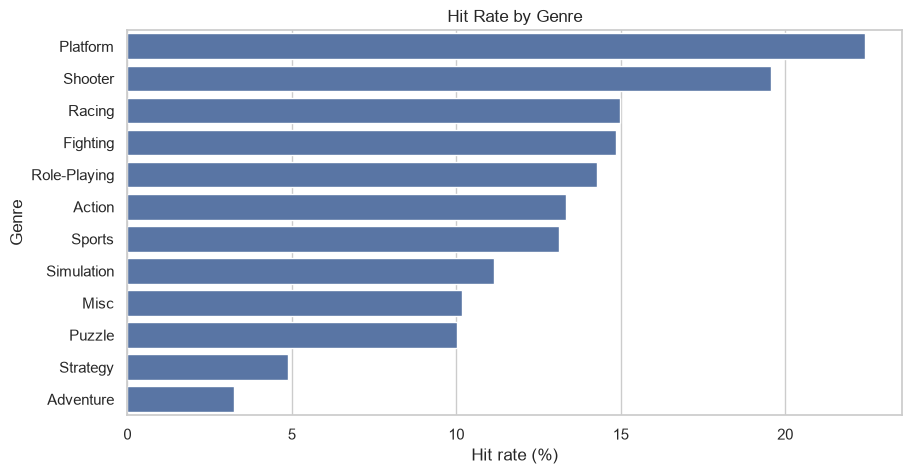

In [46]:
genre_rate = df.groupby("Genre")["Hit"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 5))
sns.barplot(x=genre_rate.values, y=genre_rate.index)
plt.title("Hit Rate by Genre")
plt.xlabel("Hit rate (%)")
plt.ylabel("Genre")
plt.savefig("charts/hit_rate_by_genre.png", dpi=150, bbox_inches="tight")
plt.show()

Platform and Shooter games are the most likely to be hits (about 1 in 5). Adventure and Strategy games rarely are (under 5%). Action has the most games, but only an average hit rate, so making lots of games in a genre doesn’t mean more hits.

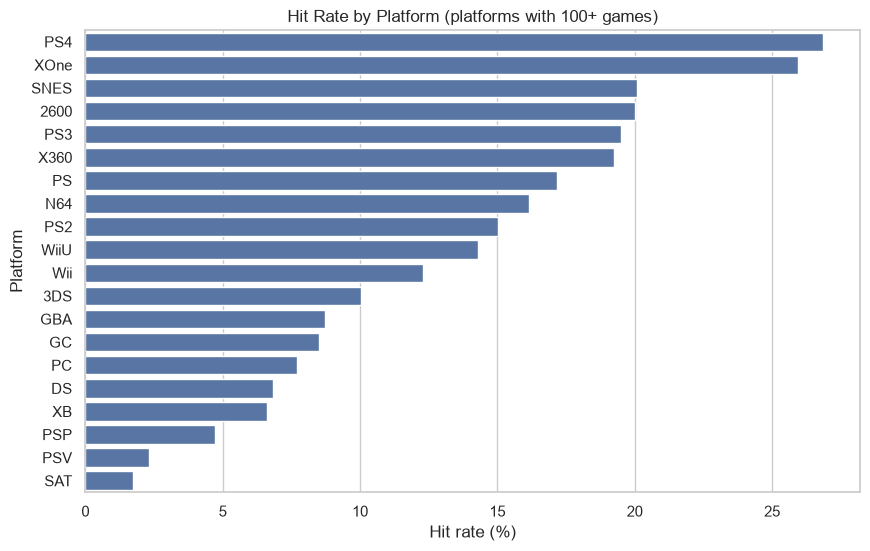

In [47]:
platform_counts = df["Platform"].value_counts()
big_platforms = platform_counts[platform_counts >= 100].index
platform_rate = df[df["Platform"].isin(big_platforms)].groupby("Platform")["Hit"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=platform_rate.values, y=platform_rate.index)
plt.title("Hit Rate by Platform (platforms with 100+ games)")
plt.xlabel("Hit rate (%)")
plt.ylabel("Platform")
plt.savefig("charts/hit_rate_by_platform.png", dpi=150, bbox_inches="tight")
plt.show()

Home consoles like PS4, Xbox One, PS3, and Xbox 360 have the highest hit rates (about 19–27%). Handhelds (DS, PSP, PS Vita) and PC have the lowest (under 8%). The Wii was a best-selling console, but only about 12% of its games were hits.

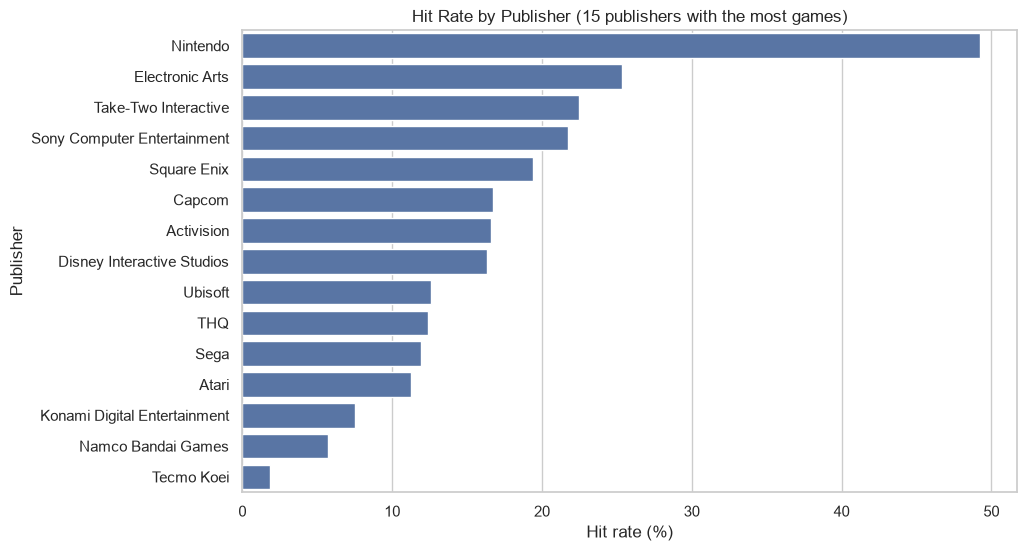

In [48]:
top_publishers = df["Publisher"].value_counts().head(15).index
publisher_rate = df[df["Publisher"].isin(top_publishers)].groupby("Publisher")["Hit"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=publisher_rate.values, y=publisher_rate.index)
plt.title("Hit Rate by Publisher (15 publishers with the most games)")
plt.xlabel("Hit rate (%)")
plt.ylabel("Publisher")
plt.savefig("charts/hit_rate_by_publisher.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
pub_table = df[df["Publisher"].isin(top_publishers)].groupby("Publisher")["Hit"].agg(Games="count", Hits="sum")
pub_table["Hit_rate_%"] = (pub_table["Hits"] / pub_table["Games"] * 100).round(1)
pub_table.sort_values("Hit_rate_%", ascending=False)

,Games,Hits,Hit_rate_%
Publisher,,,
Nintendo,686,338,49.3
Electronic Arts,1318,334,25.3
Take-Two Interactive,400,90,22.5
Sony Computer Entertainment,677,147,21.7
Square Enix,211,41,19.4
Capcom,358,60,16.8
Activision,952,158,16.6
Disney Interactive Studios,214,35,16.4
Ubisoft,905,114,12.6


Nintendo and Electronic Arts have nearly the same number of hits (about 335 each), but Nintendo needed half as many games to get there. About half of Nintendo’s games are hits, compared to 25% for EA. At the bottom, Tecmo Koei had only 6 hits out of 321 games.

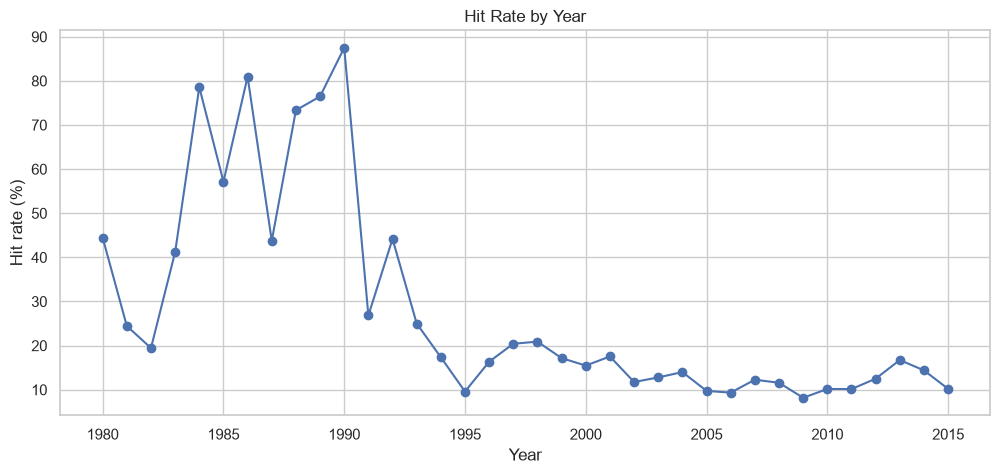

In [50]:
year_rate = df.groupby("Year")["Hit"].mean() * 100

plt.figure(figsize=(12, 5))
plt.plot(year_rate.index, year_rate.values, marker="o")
plt.title("Hit Rate by Year")
plt.xlabel("Year")
plt.ylabel("Hit rate (%)")
plt.savefig("charts/hit_rate_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

Hit rates before 1994 are high and jumpy, likely because there were few games per year and the website mostly records well-known older games. From the mid-1990s on, the hit rate stays steady at around 10–20%. 2015 falls within this normal range, so its sales seem complete enough to keep.

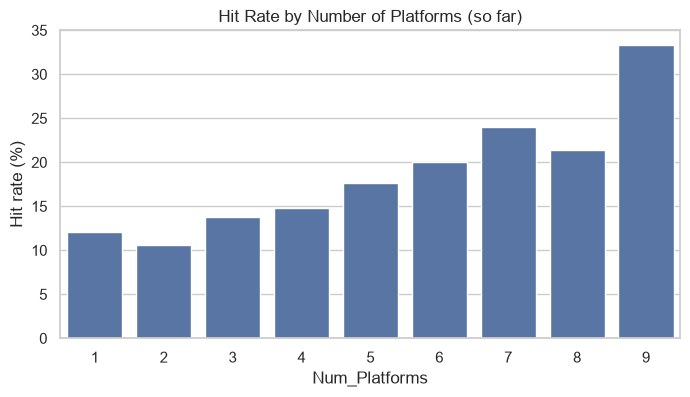

In [51]:
np_rate = df.groupby("Num_Platforms")["Hit"].mean() * 100

plt.figure(figsize=(8, 4))
sns.barplot(x=np_rate.index, y=np_rate.values)
plt.title("Hit Rate by Number of Platforms (so far)")
plt.xlabel("Num_Platforms")
plt.ylabel("Hit rate (%)")
plt.savefig("charts/hit_rate_by_num_platforms.png", dpi=150, bbox_inches="tight")
plt.show()

Games released on more consoles are more likely to be hits: about 10–12% for 1–2 consoles, rising to over 20% for 7 or more. This supports our idea that big-budget games come out on many consoles. The bars for 8–9 consoles are based on few games, so they’re less reliable.

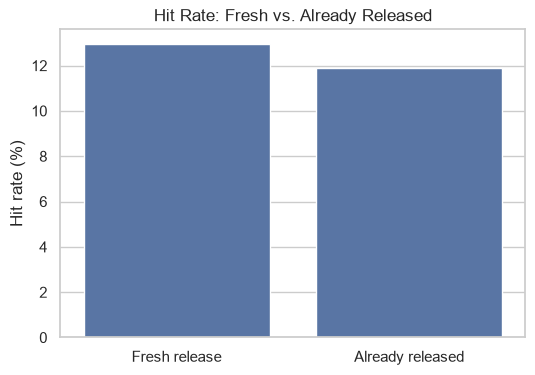

In [52]:
ar_rate = df.groupby("Already_Released")["Hit"].mean() * 100

plt.figure(figsize=(6, 4))
sns.barplot(x=ar_rate.index, y=ar_rate.values)
plt.xticks([0, 1], ["Fresh release", "Already released"])
plt.title("Hit Rate: Fresh vs. Already Released")
plt.ylabel("Hit rate (%)")
plt.xlabel("")
plt.savefig("charts/hit_rate_by_already_released.png", dpi=150, bbox_inches="tight")
plt.show()

Re-releases have almost the same hit rate as fresh releases (about 12% vs. 13%). On its own, Already_Released doesn’t seem to tell us much. Ablation will show if it helps when combined with the other features.

- Hits are rare (13%)
- Genre matters: Platform/Shooter high, Adventure/Strategy low
- Platform matters: PS4/Xbox One high, handhelds and PC low
- Publisher matters a lot: Nintendo ~49%, Tecmo Koei ~2%
- Old years look inflated, probably due to how the data was collected
- More consoles → more likely a hit
- Already_Released barely makes a difference

# Step 6: Keep only the columns we need

In [53]:
df = df[["Name", "Platform", "Year", "Genre", "Publisher", "Num_Platforms", "Already_Released", "Hit"]]
df.head()

,Name,Platform,Year,Genre,Publisher,Num_Platforms,Already_Released,Hit
0,Wii Sports,Wii,2006,Sports,Nintendo,1,0,1
1,Super Mario Bros.,NES,1985,Platform,Nintendo,1,0,1
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,1,0,1
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,1,0,1
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,1,0,1


## Step 7: Split into training and test

In [54]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, groups=df["Name"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Train:", train.shape, "| Hit rate:", round(train["Hit"].mean() * 100, 1))
print("Test:", test.shape, "| Hit rate:", round(test["Hit"].mean() * 100, 1))
print("Games in both:", len(set(train["Name"]) & set(test["Name"])))

Train: (12680, 8) | Hit rate: 13.0
Test: (3169, 8) | Hit rate: 12.4
Games in both: 0


## Step 8: Group small publishers into "Other" 

In [55]:
counts = train["Publisher"].value_counts()
big = counts[counts >= 10].index

train.loc[~train["Publisher"].isin(big), "Publisher"] = "Other"
test.loc[~test["Publisher"].isin(big), "Publisher"] = "Other"

print("Publishers in train:", train["Publisher"].nunique())
print("Publishers in test:", test["Publisher"].nunique())
print("Other in train:", (train["Publisher"] == "Other").sum())
print("Other in test:", (test["Publisher"] == "Other").sum())

Publishers in train: 133
Publishers in test: 126
Other in train: 1053
Other in test: 272


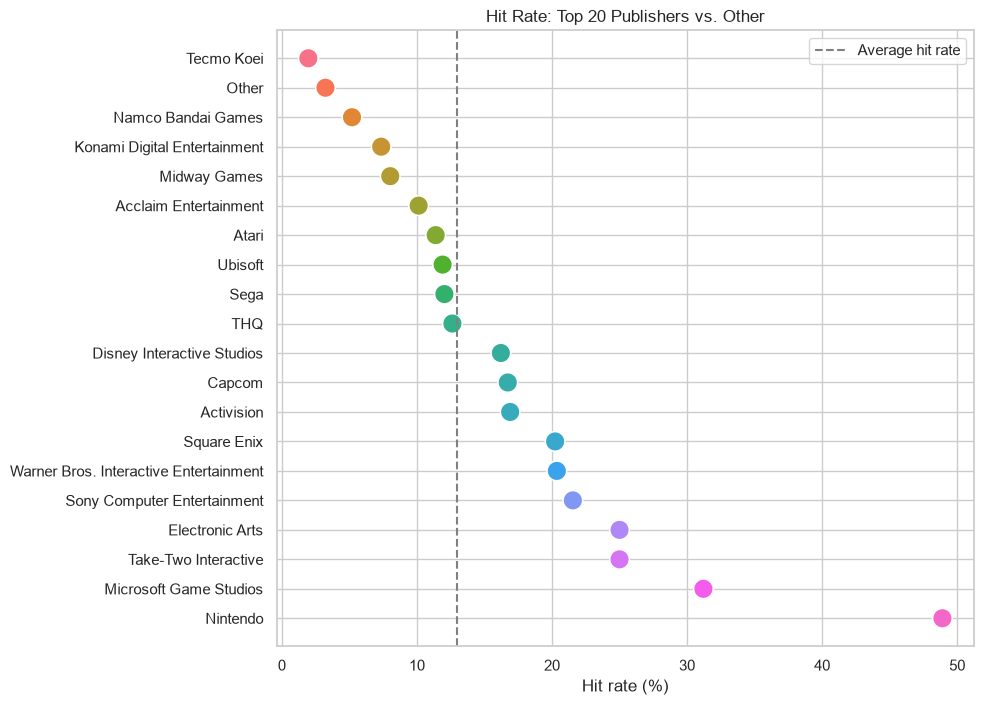

In [56]:
pub = train.groupby("Publisher")["Hit"].agg(Games="count", Hit_rate="mean")
pub["Hit_rate"] = pub["Hit_rate"] * 100

top20 = pub.sort_values("Games", ascending=False).head(20)

small = pub[pub["Games"] < 10]
other_rate = train[train["Publisher"].isin(small.index)]["Hit"].mean() * 100
other = pd.DataFrame({"Games": [small["Games"].sum()], "Hit_rate": [other_rate]}, index=["Other (small publishers)"])

plot_data = pd.concat([top20, other]).sort_values("Hit_rate")

plt.figure(figsize=(9, 8))
sns.scatterplot(x=plot_data["Hit_rate"], y=plot_data.index, hue=plot_data.index, palette="husl", s=200, legend=False)
plt.axvline(train["Hit"].mean() * 100, color="gray", linestyle="--", label="Average hit rate")
plt.title("Hit Rate: Top 20 Publishers vs. Other")
plt.xlabel("Hit rate (%)")
plt.ylabel("")
plt.legend()
plt.savefig("charts/hit_rate_top20_vs_other.png", dpi=150, bbox_inches="tight")
plt.show()

Small publishers combined (‘Other’) have a hit rate of only about 3%, far below average. Nintendo leads at about 49%, followed by Microsoft (31%) and Take-Two and EA (25%).

In [57]:
train.to_csv("data/train.csv", index=False)
test.to_csv("data/test.csv", index=False)

print("Saved!")
print("Train:", train.shape, "| Publishers:", train["Publisher"].nunique())
print("Test:", test.shape, "| Publishers:", test["Publisher"].nunique())

Saved!
Train: (12680, 8) | Publishers: 133
Test: (3169, 8) | Publishers: 126


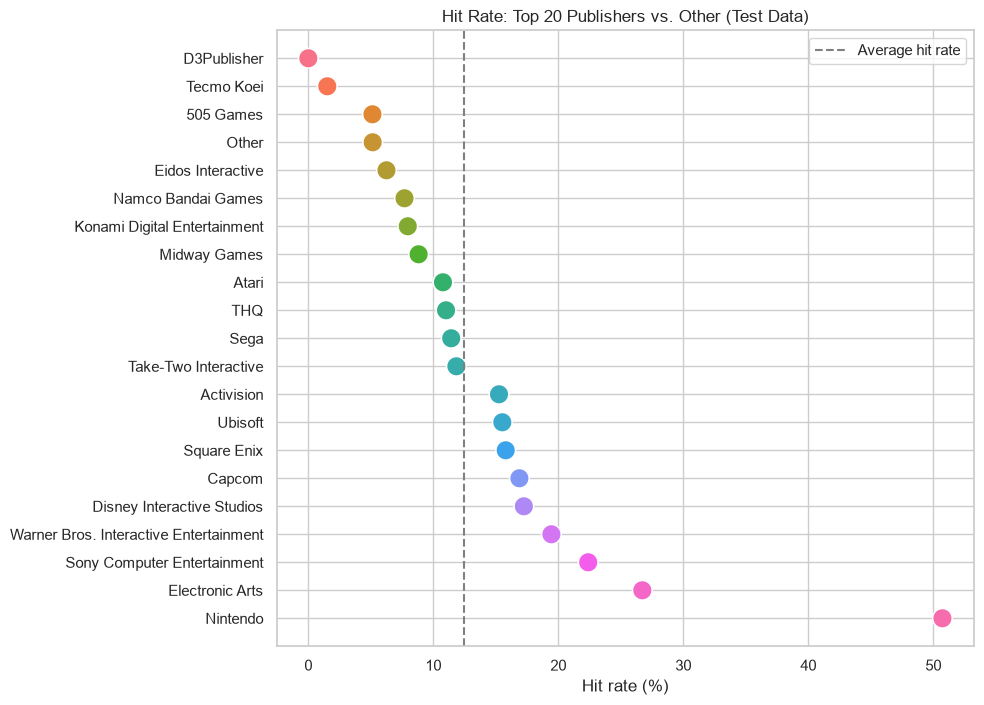

In [58]:
pub_test = test.groupby("Publisher")["Hit"].agg(Games="count", Hit_rate="mean")
pub_test["Hit_rate"] = pub_test["Hit_rate"] * 100
plot_test = pub_test.sort_values("Games", ascending=False).head(21).sort_values("Hit_rate")

plt.figure(figsize=(9, 8))
sns.scatterplot(x=plot_test["Hit_rate"], y=plot_test.index, hue=plot_test.index, palette="husl", s=200, legend=False)
plt.axvline(test["Hit"].mean() * 100, color="gray", linestyle="--", label="Average hit rate")
plt.title("Hit Rate: Top 20 Publishers vs. Other (Test Data)")
plt.xlabel("Hit rate (%)")
plt.ylabel("")
plt.legend()
plt.savefig("charts/hit_rate_top20_vs_other_test.png", dpi=150, bbox_inches="tight")
plt.show()

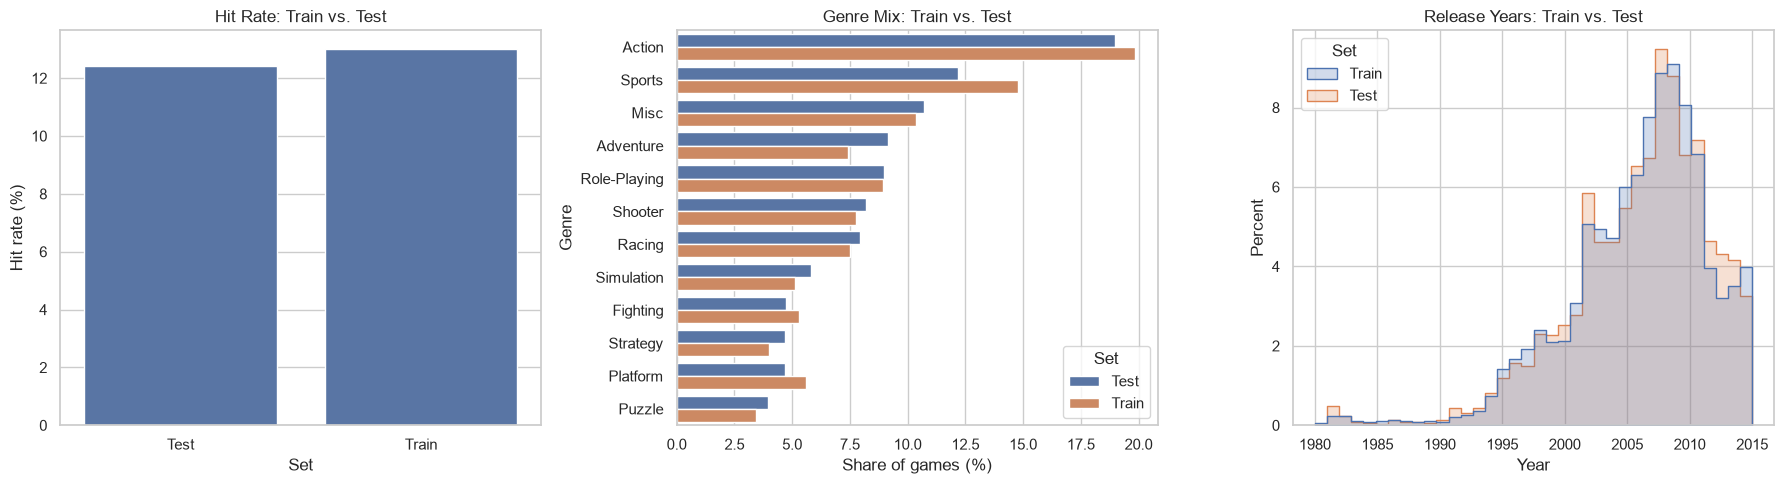

In [59]:
both = pd.concat([train.assign(Set="Train"), test.assign(Set="Test")])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

hit_share = both.groupby("Set")["Hit"].mean() * 100
sns.barplot(x=hit_share.index, y=hit_share.values, ax=axes[0])
axes[0].set_title("Hit Rate: Train vs. Test")
axes[0].set_ylabel("Hit rate (%)")

genre_share = both.groupby("Set")["Genre"].value_counts(normalize=True).mul(100).rename("Percent").reset_index()
sns.barplot(data=genre_share, x="Percent", y="Genre", hue="Set", ax=axes[1])
axes[1].set_title("Genre Mix: Train vs. Test")
axes[1].set_xlabel("Share of games (%)")

sns.histplot(data=both, x="Year", hue="Set", stat="percent", common_norm=False, element="step", bins=36, ax=axes[2])
axes[2].set_title("Release Years: Train vs. Test")

plt.tight_layout()
plt.savefig("charts/train_vs_test_split_check.png", dpi=150, bbox_inches="tight")
plt.show()

We checked that the training and test data look alike. Hit rates are close (13.0% vs. 12.4%), the genre mix is similar (biggest gap: Sports, about 3%), and both have the same spread of release years. So the split is fair, and the test data is a good stand-in for new games.

In [63]:
# Exploratory Data Analysis Summary

print("Total games:", len(df))

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nHit vs Non-Hit Distribution:")
print(df["Hit"].value_counts())

print("\nHit Percentages:")
print(df["Hit"].value_counts(normalize=True) * 100)

print("\nOverall Hit Rate:")
hit_rate = df["Hit"].mean() * 100
print(f"{hit_rate:.2f}%")

print("\nHit Rate by Genre:")
genre_hits = (
    df.groupby("Genre")["Hit"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

genre_hits["mean"] *= 100
print(genre_hits)

Total games: 15849

Dataset columns:
['Name', 'Platform', 'Year', 'Genre', 'Publisher', 'Num_Platforms', 'Already_Released', 'Hit']

Missing values:
Name                0
Platform            0
Year                0
Genre               0
Publisher           0
Num_Platforms       0
Already_Released    0
Hit                 0
dtype: int64

Hit vs Non-Hit Distribution:
Hit
0    13807
1     2042
Name: count, dtype: int64

Hit Percentages:
Hit
0    87.115906
1    12.884094
Name: proportion, dtype: float64

Overall Hit Rate:
12.88%

Hit Rate by Genre:
              count       mean
Genre                         
Platform        860  22.441860
Shooter        1247  19.566961
Racing         1202  14.975042
Fighting        821  14.859927
Role-Playing   1416  14.265537
Action         3116  13.350449
Sports         2258  13.108946
Simulation      834  11.151079
Misc           1653  10.163339
Puzzle          558  10.035842
Strategy        654   4.892966
Adventure      1230   3.252033


## Exploratory Data Analysis: Key Findings

### 1. Overall Video Game Success

After preprocessing, our dataset contains 15,849 video game records. Of these, 2,042 (12.88%) were classified as hits, meaning they sold at least one million copies worldwide.

The remaining 87.12% were classified as non-hits. This class imbalance is important because a machine learning model could achieve high accuracy by predicting that every game will be unsuccessful.

### 2. Genre and Commercial Success

Platform games had the highest hit rate at 22.44%, followed by Shooter games at 19.57%. Adventure games had the lowest hit rate at 3.25%.

These differences suggest that genre is associated with commercial success, although genre alone cannot determine whether a game will become a hit.

### 3. Publisher and Commercial Success

Our publisher analysis shows that hit rates vary substantially across major publishers. Nintendo had a particularly high hit rate compared with other publishers in the dataset.

This supports investigating publisher as a predictive feature, although differences in game portfolios, release periods, and other factors may contribute to the observed patterns.

### 4. Implications for Machine Learning

The exploratory analysis suggests that publisher, genre, and platform may help distinguish successful games from unsuccessful ones.

Because the dataset is imbalanced, we should evaluate our classification models using precision, recall, and F1-score rather than relying on accuracy alone.

### 5. Limitations

The dataset contains historical video game sales and does not include factors such as marketing budgets, development costs, review scores, or game quality. Therefore, our results describe associations within this dataset and may not generalize to future releases.